In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2 as cv
import hyperspy.api as hs
import json
from scipy.optimize import curve_fit
import pint
print('pint', pint.__version__)

import sys
print('python', sys.version)
print('hs', hs.__version__)
print('cv', cv.__version__)
print('numpy', np.__version__)
print('pd', pd.__version__)


plt.rcParams.update({'font.size': 22})


#from os.path import join, dirname, abspath, split, exists
#from os import listdir, makedirs
#import particlespy.api as ps
#from skimage.feature import peak_local_max
#from skimage.segmentation import watershed, clear_border
#from skimage.measure import regionprops, regionprops_table
#from scipy import ndimage as ndi


pint 0.19.2
python 3.9.7 (tags/v3.9.7:1016ef3, Aug 30 2021, 20:19:38) [MSC v.1929 64 bit (AMD64)]
hs 1.7.0
cv 4.5.5
numpy 1.21.2
pd 1.3.3


In [2]:
#%matplotlib qt


imgPath = r'D:\2024-05-30\AM87-LCD10'

In [3]:
imgHS = hs.load(imgPath)
#dir(imgHS)

#plt.imshow(imgHS.data)
imgTMP = TEMimg(imgPath)
imgTMP.blur(21)
imgTMP.adaptBin(sqr=351, offset=20)
imgTMP.histo(1.6)
#imgTMP.save()
dir(imgTMP)


ValueError: No filename matches the pattern "D:\2024-05-30\AM87-LCD10"

In [12]:
class TEMimg:
    def __init__(self, imgPath):
        
        self.NFO = {}
        self.NFO['path'] = imgPath
        print(self.NFO['path'])
        self.steps = {}
        self.load()
        
    def load(self, minCnt = 4):
        
        imgHS = hs.load(self.NFO['path'])
        self.metadataDict = imgHS.original_metadata
        minVal, maxVal = np.min(imgHS.data), np.max(imgHS.data)
        imgTemp = np.rint((imgHS.data-minVal)*255/(maxVal-minVal)).astype(np.uint8)
        hist = cv.calcHist([imgTemp],[0],None,[256],[1,256])
        pixCut = 0
        for i, j in enumerate(reversed(hist)):
            if j >= minCnt:
                pixCut = 255-i
                break
        imgTemp = np.ma.masked_where(imgTemp > pixCut, imgTemp)
        imgTemp = (imgTemp)*255./np.max(imgTemp)
        self.img = imgTemp.astype(np.uint8)
        self.NFO['name'] = self.metadataDict['ImageList']['TagGroup0']['Name']
        self.NFO['spec'] = self.metadataDict['ImageList']['TagGroup0']['ImageTags']['Session Info']['Specimen']
        self.NFO['operator'] = self.metadataDict['ImageList']['TagGroup0']['ImageTags']['Session Info']['Operator']
        self.NFO['microscope'] = self.metadataDict['ImageList']['TagGroup0']['ImageTags']['Session Info']['Microscope']
        self.NFO['calib'] = self.metadataDict['ImageList']['TagGroup0']['ImageData']['Calibrations']['Dimension']['TagGroup0']['Scale']

    def blur(self, mtrx = 9):
    
        self.img = cv.GaussianBlur(self.img, (mtrx, mtrx), 0)
        self.steps['blur'] = 'mtrx = {}'.format(mtrx) 
        
    def adaptBin(self, sqr=351, offset=15):
        
        imgBinTMP = cv.adaptiveThreshold(self.img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY_INV, sqr, offset)
        contours, hierarchy = cv.findContours(imgBinTMP, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
        self.imgBin = imgBinTMP
        self.overlayBin = cv.drawContours(cv.cvtColor(self.img, cv.COLOR_GRAY2RGB), contours, -1, (0, 255, 0), 2)
        self.steps['adaptBin'] = 'sqr = {}, offset = {}'.format(sqr, offset) 
        
    def histo(self, cutoff_low = 0.0, cutoff_high = 10000):
        
        sizesTMP, cnts = [], []
        contours, hierarchy = cv.findContours(self.imgBin, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
        imgH, imgW = imgTMP.imgBin.shape
        for contour in contours:
            area = cv.contourArea(contour)*self.NFO['calib']*self.NFO['calib']
            size = np.sqrt(4.*area/np.pi)
            x, y, W, H = cv.boundingRect(contour)
            if x!=0 and y!=0 and x+W!=imgW and y+H!=imgH:
                if (size > cutoff_low) and (size < cutoff_high):
                    cnts.append(contour)
                    sizesTMP.append(size)
        self.cutoff = [cutoff_low, cutoff_high]
        self.sizes = sizesTMP
        self.overlayHist = cv.drawContours(cv.cvtColor(self.img, cv.COLOR_GRAY2RGB), cnts, -1, (0, 255, 0), 2)
        self.steps['histo'] = 'cutoff = {}'.format(self.cutoff)
    
    def save(self):
        
        head, tail = os.path.split(imgTMP.NFO['path'])        
        if not os.path.exists(os.path.join(head, 'analysis')):
            os.makedirs(os.path.join(head, 'analysis'))
        savePath = os.path.join(head, 'analysis', tail.split('.dm3')[0])
        plt.imsave('{}_overlay.png'.format(savePath), self.overlayHist)
        with open('{}.params'.format(savePath), 'w') as file:
            file.write(json.dumps(self.steps))
        with open('{}.hist'.format(savePath), 'w') as output:
            output.write('Size (nm)' + '\n')
            for size in self.sizes:
                output.write(str(size) + '\n')
        
        

In [13]:
class TEMana:
    def __init__(self, foldPath):

        
        self.pathTemp = os.path.join(foldPath, 'analysis')
        head, self.sampleName = os.path.split(foldPath)
        self.histRead()
        #self.saveHisto()
        
    def gauss_function(self, x, a, x0, sigma):
        
        return a*np.exp(-(x-x0)**2/(2*sigma**2))

    def histRead(self):
        
        self.dfList, self.histList = [], []
        for file in os.listdir(self.pathTemp):
            
            if file.split('.')[-1] == 'hist':
                histTpm = pd.read_csv(os.path.join(self.pathTemp, file), decimal='.', header = [0])
                self.dfList.append(histTpm)
                self.histList.append(file)
        self.dfConcat = pd.concat(self.dfList, ignore_index=True)
        
    def saveHisto(self, binwidth = 0.5):
        
        self.binwidth = binwidth
        for i, hist in enumerate(self.dfList):
            plt.close()
            bins=np.arange(hist['Size (nm)'].min(), hist['Size (nm)'].max() + self.binwidth, self.binwidth)
            plt.hist(hist, bins=bins)
            plt.xlabel('Size (nm)')
            plt.ylabel('Frequency (a.u.)')
            plt.savefig(os.path.join(self.pathTemp, '{}_Hplot.jpg'.format(self.histList[i].split('.hist')[0])))
        self.fitHisto()
        xs = np.linspace(self.dfConcat.min(), self.dfConcat.max(), 1000)
        plt.close()
        bins=np.arange(self.dfConcat['Size (nm)'].min(), self.dfConcat['Size (nm)'].max() + self.binwidth, self.binwidth)
        plt.hist(self.dfConcat['Size (nm)'], bins=bins, label = '{}'.format(self.dfConcat.shape[0]))
        self.dfConcat.to_csv(os.path.join(self.pathTemp, 'result.hist'), sep='\t', index=False)
        try: 
            plt.plot(xs, self.gauss_function(xs, *self.popt), linestyle = '--', color = 'black', label = 'Avg size = {:.1f} nm\nSigma = {:.2f} nm'.format(self.popt[1], self.popt[2]))
        except AttributeError:
            pass
        plt.xlabel('NPs size (nm)')
        plt.ylabel('Frequency')
        plt.title(self.sampleName)
        plt.legend()
        plt.savefig(os.path.join(self.pathTemp, 'result.pdf'))
        
    
    def fitHisto(self):
        
        bins=np.arange(self.dfConcat['Size (nm)'].min(), self.dfConcat['Size (nm)'].max() + self.binwidth, self.binwidth)
        npHist = np.histogram(self.dfConcat['Size (nm)'], bins, density = False)
        frequencies = npHist[0]
        bincentres = [(npHist[1][i]+npHist[1][i+1])/2. for i in range(len(npHist[1])-1)]
        n = len(bincentres)  
        mean = sum(bincentres * frequencies) / sum(frequencies)
        sigma = np.sqrt(sum(frequencies * (bincentres - mean)**2) / sum(frequencies))
        try: self.popt, self.pcov = curve_fit(self.gauss_function, bincentres, frequencies, p0=[max(frequencies), mean, sigma], maxfev=5000)
        except RuntimeError:
            print('Couldn\'t fit')
            pass


In [14]:
rootPath = r'C:\DataCNRS\DropSU\Experimental\TEM\DATA' #Axel
#rootPath = r'C:\DataCNRS\DropSU\Experimental\TEM\DATA\aslhey' #Ashley

syntheses = {'july2022batch':{
                '1a':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-24_FCMAT-1011\1a', 
                '1b':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-29_FCMAT-1011\1b', # aggloméré
                '1c':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-29_FCMAT-1011\1c', # aggloméré
                '1d':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-24_FCMAT-1011\1d', # trop de NPs
                '2a':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-29_FCMAT-1011\2a',
                '2b':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-29_FCMAT-1011\2b', # trop de NPs
                '2c':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-29_FCMAT-1011\2c',
                '2d':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-06-29_FCMAT-1011\2d',
                '3a':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-07-01_FCMAT-1011\3a',
                '3b':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-07-01_FCMAT-1011\3b',
                '3c':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-07-01_FCMAT-1011\3c',
                '3d':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-07-01_FCMAT-1011\3d',
                '4b':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-10-06_FCMAT-1011\4B', # un peu aggloméré
                '5b':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2022-10-06_FCMAT-1011\5B',
                '2Dbis':r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2023-03-14_FCMAT-1011\2D'},
             'SindaBatch':{
                 'SS16':r'2023-03-22_FCMAT-1011\230317 SS16 d800',
                 'SS24':r'2023-03-27_FCMAT-1011\240323 SS24 Au6Cu4- D 3200',
                 'SS37':r'2023-06-09_FCMAT-1011\ss37-d800',
                 'SS41':r'2023-05-26_FCMAT-1011\SS41-D800',
                 'SS43':r'2023-05-26_FCMAT-1011\SS43-D800',
                 'SS45':r'2023-05-26_FCMAT-1011\SS45-D800',
                 'SS47':r'2023-05-26_FCMAT-1011\SS47-D800',
                 'SS53':r'2023-05-26_FCMAT-1011\SS53-D800',
                 'SS55':r'2023-06-02_FCMAT-1011\SS55-d800',
                 'SS57':r'2023-06-02_FCMAT-1011\SS57-d800',
                 'SS60':r'2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800'},
             'AshleyBatch':{
                 'AM87':r'2024-05-30_FCMAT_1011\AM87-LCD10',
                 'AM92-LCD10':r'2024-06-28_FCMAT_1011\AM92-LCD10',
                 'AM96-LCD10':r'2024-07-05_FCMAT_1011\AM96-LCD10',
                 'AM98_LCD20':r'2024-07-10_FCMAT_1011\AM98_LCD20',
                 'AM98_LCDCM_D20':r'2024-07-10_FCMAT_1011\AM98_LCDCM_D20'
                 }
                }



In [15]:
os.path.exists(os.path.join(rootPath, syntheses['SindaBatch']['SS60']))

True

C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0001.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0003.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0004.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0005.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0006.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0007.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0008.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0009.dm3
C:\DataCNRS\DropSU\Experimental\TEM\DATA\2023-07-18_FCMAT-1011\SS60-Au45Cu55-D80

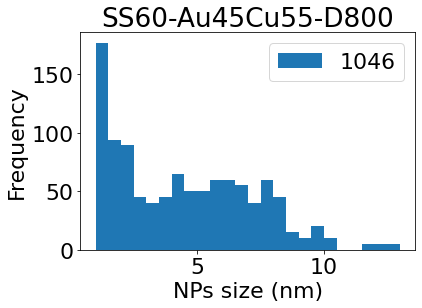

In [40]:
sampleList = ['SS60']
for sample in sampleList:
    toAnalysePath = os.path.join(rootPath, syntheses['SindaBatch'][sample])
    for file in os.listdir(toAnalysePath):
        if ('60kX' in file) and ('dm3' in file):
            imgTMP = TEMimg(os.path.join(toAnalysePath, file))
            imgTMP.blur(21)
            imgTMP.adaptBin(sqr=351, offset=20)
            imgTMP.histo(2)
            imgTMP.save()
    anaTMP = TEMana(toAnalysePath)
    anaTMP.saveHisto(binwidth = 0.5)

Couldn't fit


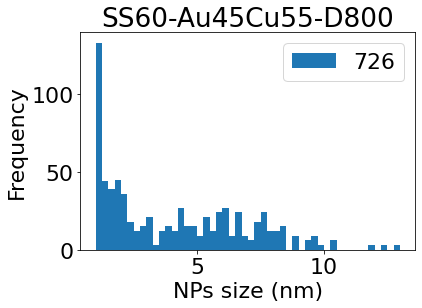

In [38]:
anaTMP.saveHisto(binwidth = 0.25)

In [9]:
imgTMP.save()

In [10]:
pathTemps = r'C:\DataCNRS\MyCore\Experimental\TEM\RawData\2023-06-02_FCMAT-1011\SS55-d800\analysis'
samplePath = join(pathTemps, 'result.hist')
samplePath

NameError: name 'join' is not defined

In [23]:
def gauss_function(self, x, a, x0, sigma):
        
        return a*np.exp(-(x-x0)**2/(2*sigma**2))

In [24]:

df = pd.read_csv(samplePath, delimiter='\t')
df

,Size (nm)
0,2.542695
1,3.417036
2,2.915563
3,3.951578
4,3.459137
...,...
618,5.381252
619,5.147117
620,5.926627
621,4.909858


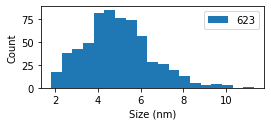

In [30]:
xs = np.linspace(df.min(), df.max(), 1000)
binwidth = 0.5
bins=np.arange(df['Size (nm)'].min(), df['Size (nm)'].max() + binwidth, binwidth)
plt.figure(figsize=(4,1.5))
plt.hist(df['Size (nm)'], bins=bins, label = '{}'.format(df.shape[0]))
plt.xlabel('Size (nm)')
plt.ylabel('Count')
plt.legend()

savepath = r'C:\DataCNRS\MyCore\Experimental\TEM\METSA\2023-06-02_MPQ'
plt.savefig(join(savepath, 'histo.pdf'))